# Credit Card Fraud Detection — Advanced End-Semester Project

**Objective:** build and evaluate a fraud-detection system for a highly imbalanced transaction dataset.

This notebook includes data validation, exploratory analysis, leakage-aware preprocessing, six model families, imbalance handling, validation-based threshold selection, hyperparameter tuning, explainability, robustness checks, and a manual prediction demo.

**Dataset:** `creditcard.csv` with numeric transaction features and target column `Class` (`0 = legitimate`, `1 = fraud`). Upload the CSV to the Colab session or mount Google Drive.

## 1. Install dependencies

In [ ]:
!pip -q install imbalanced-learn xgboost shap

## 2. Imports and reproducibility

In [ ]:
import os, time, warnings, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, fbeta_score, accuracy_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, balanced_accuracy_score, matthews_corrcoef
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import calibration_curve

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 3. Load the dataset
If the file is not already in the Colab working directory, use the upload cell.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Select creditcard.csv

In [ ]:
DATA_PATH = "creditcard.csv"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Upload creditcard.csv or set DATA_PATH to its correct path."
    )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
display(df.head())

Shape: (41683, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


## 4. Data validation and cleaning
The target is not imputed: rows with an unknown target cannot safely be labelled as fraud or legitimate. Invalid target labels are removed. Missing/infinite feature values are handled later inside a pipeline, fitted on training data only.

In [ ]:
if "Class" not in df.columns:
    raise ValueError("Expected target column 'Class' was not found.")

df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
df["Class"] = df["Class"].replace([np.inf, -np.inf], np.nan)
before = len(df)
df = df.dropna(subset=["Class"]).copy()
df = df[df["Class"].isin([0, 1])].copy()
df["Class"] = df["Class"].astype("int8")

# Convert feature columns to numeric; unexpected strings become NaN and are imputed later.
feature_cols = [c for c in df.columns if c != "Class"]
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Rows removed due to missing/invalid target: {before - len(df):,}")
print("Remaining shape:", df.shape)
print("Target counts:\n", df["Class"].value_counts(dropna=False))
print("Feature missing values:", int(df[feature_cols].isna().sum().sum()))
print("Feature infinite values:", int(np.isinf(df[feature_cols].select_dtypes(include=np.number)).sum().sum()))
if df["Class"].nunique() != 2:
    raise ValueError("The cleaned target must contain both classes 0 and 1.")

Rows removed due to missing/invalid target: 1
Remaining shape: (41682, 31)
Target counts:
 Class
0    41574
1      108
Name: count, dtype: int64
Feature missing values: 0
Feature infinite values: 0


## 5. Exploratory data analysis

,count,percentage
Class,,
Legitimate (0),41574,99.7409
Fraud (1),108,0.2591


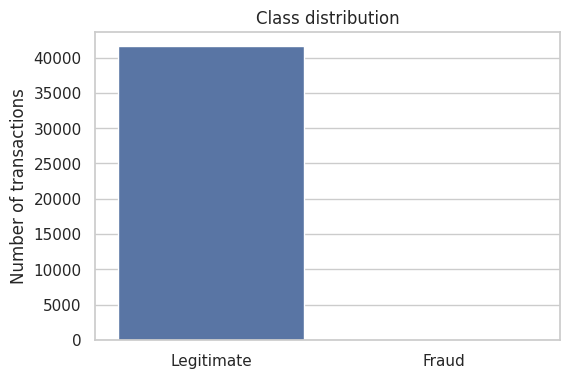

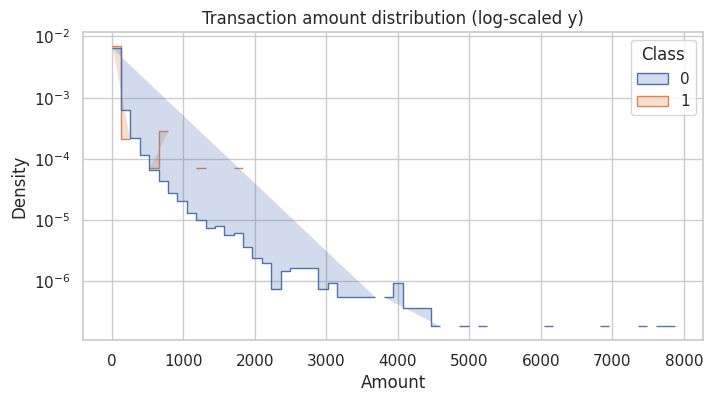

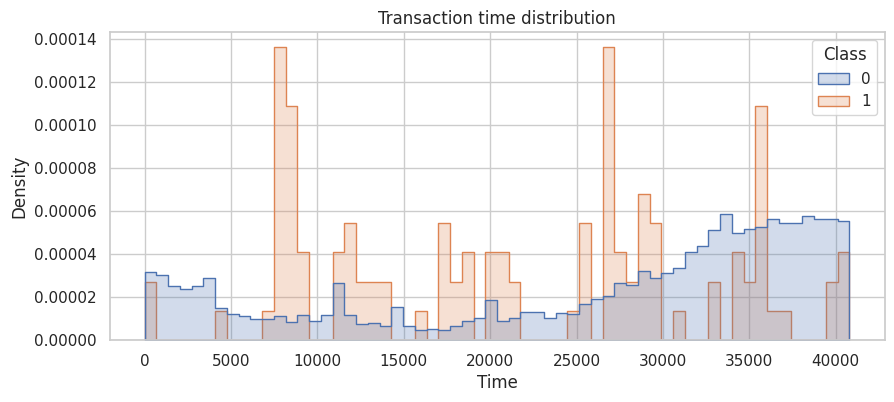

Descriptive statistics:


Amount                                                         
         count       mean         std  min   25%    50%    75%      max
Class                                                                  
0      41574.0  89.092554  237.129967  0.0  7.55  24.00  80.00  7879.42
1        108.0  93.512593  250.863273  0.0  1.00   2.32  99.99  1809.68

In [ ]:
class_counts = df["Class"].value_counts().sort_index()
display(pd.DataFrame({
    "count": class_counts,
    "percentage": (class_counts / len(df) * 100).round(4)
}).rename(index={0:"Legitimate (0)", 1:"Fraud (1)"}))

plt.figure(figsize=(6,4))
sns.barplot(x=["Legitimate", "Fraud"], y=[class_counts.get(0,0), class_counts.get(1,0)])
plt.title("Class distribution")
plt.ylabel("Number of transactions")
plt.show()

plt.figure(figsize=(8,4))
sns.histplot(data=df, x="Amount", hue="Class", bins=60, stat="density",
             common_norm=False, log_scale=(False, True), element="step")
plt.title("Transaction amount distribution (log-scaled y)")
plt.show()

if "Time" in df.columns:
    plt.figure(figsize=(10,4))
    sns.histplot(data=df, x="Time", hue="Class", bins=60, element="step",
                 stat="density", common_norm=False)
    plt.title("Transaction time distribution")
    plt.show()

print("Descriptive statistics:")
display(df.groupby("Class")[["Amount"]].describe() if "Amount" in df.columns else df.groupby("Class").size())

## 6. Feature engineering
`Amount_log` reduces the skew of transaction amounts. `Hour` is derived from the dataset's elapsed-time field where available. These are deterministic transformations of existing features, not information from the target.

In [ ]:
data = df.copy()

if "Amount" in data.columns:
    data["Amount_log"] = np.log1p(data["Amount"].clip(lower=0))

if "Time" in data.columns:
    # Common credit-card dataset: Time is seconds elapsed from the first transaction.
    data["Hour"] = ((data["Time"] // 3600) % 24).astype(float)

X = data.drop(columns=["Class"])
y = data["Class"].astype(int)

# Remove columns that contain no usable information.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print("Dropping all-missing columns:", all_missing)
    X = X.drop(columns=all_missing)

print("Feature matrix:", X.shape)
print("Target:", y.shape)

Feature matrix: (41682, 32)
Target: (41682,)


## 7. Train, validation and test split
The test set is held back until final evaluation. The validation set is used for threshold selection and model selection. Stratification preserves the rare fraud proportion in each split.

In [ ]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("Train:", X_train.shape, "Fraud:", int(y_train.sum()))
print("Validation:", X_val.shape, "Fraud:", int(y_val.sum()))
print("Test:", X_test.shape, "Fraud:", int(y_test.sum()))

Train: (26676, 32) Fraud: 69
Validation: (6669, 32) Fraud: 17
Test: (8337, 32) Fraud: 22


## 8. Evaluation utilities
Accuracy alone is misleading on an imbalanced dataset. We report precision, recall, F1, F2, ROC-AUC, PR-AUC (average precision), balanced accuracy, and MCC. PR-AUC and recall are especially informative for fraud detection.

In [ ]:
def get_scores(model, X_part):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_part)[:, 1]
    if hasattr(model, "decision_function"):
        raw = model.decision_function(X_part)
        return (raw - np.min(raw)) / (np.max(raw) - np.min(raw) + 1e-12)
    raise ValueError("Model does not provide probability or decision scores.")

def metrics_at_threshold(y_true, scores, threshold=0.5):
    pred = (np.asarray(scores) >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "mcc": matthews_corrcoef(y_true, pred)
    }

def choose_threshold_for_f2(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    # precision/recall have one more element than thresholds.
    f2 = (5 * precision[:-1] * recall[:-1]) / (4 * precision[:-1] + recall[:-1] + 1e-12)
    idx = int(np.nanargmax(f2))
    return float(thresholds[idx]), float(f2[idx])

def evaluate_predictions(name, y_true, scores, threshold=0.5, show_matrix=True):
    m = metrics_at_threshold(y_true, scores, threshold)
    print(f"\n{name}")
    display(pd.DataFrame([m]).set_index(pd.Index([name])))
    pred = (np.asarray(scores) >= threshold).astype(int)
    print(classification_report(y_true, pred, target_names=["Legitimate", "Fraud"], zero_division=0))
    if show_matrix:
        ConfusionMatrixDisplay.from_predictions(
            y_true, pred, display_labels=["Legitimate", "Fraud"], values_format="d"
        )
        plt.title(f"{name} — threshold {threshold:.4f}")
        plt.show()
    return m

## 9. Define models and fit on training data
All imputers/scalers are inside sklearn pipelines, so they learn only from the training split. Class weights are used where supported. SMOTE is demonstrated separately in Section 11 and is applied only inside the training pipeline.

In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1500, class_weight="balanced",
            random_state=RANDOM_STATE, solver="liblinear"
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=120, max_depth=16, class_weight="balanced_subsample",
            min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
}

fitted_models, fit_times, validation_scores = {}, {}, {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    fit_times[name] = time.time() - start
    fitted_models[name] = model
    validation_scores[name] = get_scores(model, X_val)
    print(f"{name}: trained in {fit_times[name]:.2f} seconds")


Logistic Regression: trained in 1.30 seconds
Random Forest: trained in 18.23 seconds


## 10. Compare baseline models on validation data
This comparison uses the default 0.50 threshold. Ranking by PR-AUC is generally more meaningful than ranking by accuracy for a rare-event problem.

,threshold,precision,recall,f1,f2,roc_auc,pr_auc,balanced_accuracy,mcc,fit_seconds
model,,,,,,,,,,
Random Forest,0.5,1.0000,0.8235,0.9032,0.8537,0.9999,0.9710,0.9118,0.9073,18.2324
Logistic Regression,0.5,0.1318,1.0000,0.2329,0.4315,0.9995,0.7984,0.9916,0.3600,1.2995


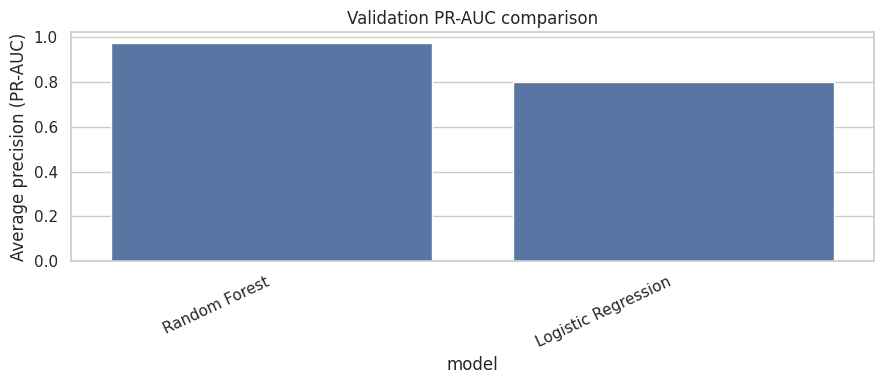

In [ ]:
comparison = []
for name, scores in validation_scores.items():
    row = metrics_at_threshold(y_val, scores, 0.5)
    row["model"] = name
    row["fit_seconds"] = fit_times[name]
    comparison.append(row)

comparison_df = pd.DataFrame(comparison).set_index("model").sort_values("pr_auc", ascending=False)
display(comparison_df.round(4))

plt.figure(figsize=(9,4))
sns.barplot(data=comparison_df.reset_index(), x="model", y="pr_auc")
plt.xticks(rotation=25, ha="right")
plt.title("Validation PR-AUC comparison")
plt.ylabel("Average precision (PR-AUC)")
plt.tight_layout()
plt.show()

## 11. SMOTE experiment (training data only)
SMOTE must never be applied before splitting. This experiment compares a scaled Logistic Regression model trained with SMOTE against the class-weighted Logistic Regression baseline. It is not guaranteed to improve results; the validation metrics decide.

In [ ]:
# Candidate models include supervised baselines, SMOTE LR, and Isolation Forest.
candidate_scores = dict(validation_scores)


candidate_rows = []
candidate_thresholds = {}
for name, scores in candidate_scores.items():
    threshold, best_f2 = choose_threshold_for_f2(y_val, scores)
    candidate_thresholds[name] = threshold
    row = metrics_at_threshold(y_val, scores, threshold)
    row["model"] = name
    row["best_validation_f2"] = best_f2
    candidate_rows.append(row)

threshold_results = pd.DataFrame(candidate_rows).set_index("model").sort_values("pr_auc", ascending=False)
display(threshold_results.round(4))

# Choose best PR-AUC as primary ranking metric; use validation F2 threshold for classification.
best_model_name = threshold_results.index[0]
best_threshold = candidate_thresholds[best_model_name]
print("Selected model:", best_model_name)
print("Selected validation threshold:", best_threshold)

,threshold,precision,recall,f1,f2,roc_auc,pr_auc,balanced_accuracy,mcc,best_validation_f2
model,,,,,,,,,,
Random Forest,0.2914,0.8889,0.9412,0.9143,0.9302,0.9999,0.9710,0.9704,0.9144,0.9302
Logistic Regression,1.0000,0.8000,0.9412,0.8649,0.9091,0.9995,0.7984,0.9703,0.8674,0.9091


Selected model: Random Forest
Selected validation threshold: 0.2914385748055711


## 14. Precision-recall and ROC curves

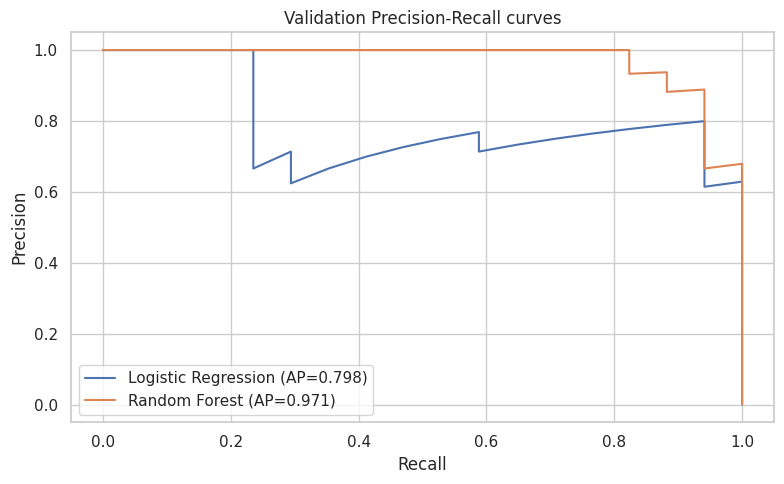

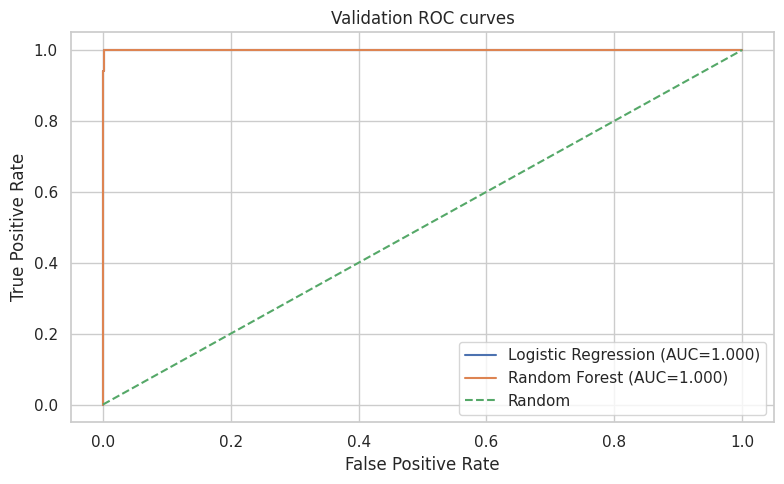

In [ ]:
plt.figure(figsize=(8,5))
for name, scores in candidate_scores.items():
    p, r, _ = precision_recall_curve(y_val, scores)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_val, scores):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall curves")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
for name, scores in candidate_scores.items():
    fpr, tpr, _ = roc_curve(y_val, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_val, scores):.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC curves")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Hyperparameter tuning — Random Forest
This is a bounded randomized search to keep Colab runtime manageable. It optimizes average precision using cross-validation on the training split only. Set `n_iter` lower if runtime is constrained.

In [ ]:
# Fast Section 15 replacement (~10-15 seconds)
rf_search_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample", n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])
rf_param_dist = {
    "model__n_estimators": [80, 120],
    "model__max_depth": [12, 16],
    "model__min_samples_leaf": [2, 4],
    "model__max_features": ["sqrt"]
}
rf_search = RandomizedSearchCV(
    rf_search_pipe, rf_param_dist, n_iter=2,
    scoring="average_precision", cv=2,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
rf_search.fit(X_train, y_train)
tuned_rf = rf_search.best_estimator_
print("Best CV PR-AUC:", rf_search.best_score_)
print("Best parameters:", rf_search.best_params_)
tuned_rf_val_scores = get_scores(tuned_rf, X_val)
display(pd.DataFrame([metrics_at_threshold(y_val, tuned_rf_val_scores, 0.5)]))

Fitting 2 folds for each of 2 candidates, totalling 4 fits
Best CV PR-AUC: 0.8524396613179828
Best parameters: {'model__n_estimators': 120, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 12}


,threshold,precision,recall,f1,f2,roc_auc,pr_auc,balanced_accuracy,mcc
0,0.5,1.0,0.823529,0.903226,0.853659,0.999885,0.966674,0.911765,0.907281


## 16. Final model selection and untouched test evaluation
The tuned Random Forest is included as a candidate. The model with the highest validation PR-AUC is selected. Its threshold is chosen on validation data. Only now is the test set evaluated.

,threshold,precision,recall,f1,f2,roc_auc,pr_auc,balanced_accuracy,mcc
model,,,,,,,,,
Random Forest,0.2997,0.8421,0.9412,0.8889,0.9195,0.9999,0.9667,0.9704,0.8900
Logistic Regression,1.0000,0.8000,0.9412,0.8649,0.9091,0.9995,0.7984,0.9703,0.8674


Final selected model: Random Forest
Final threshold: 0.2996527926141599

Random Forest — untouched test set


,threshold,precision,recall,f1,f2,roc_auc,pr_auc,balanced_accuracy,mcc
Random Forest — untouched test set,0.299653,0.703704,0.863636,0.77551,0.826087,0.952222,0.853269,0.931337,0.778945


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      8315
       Fraud       0.70      0.86      0.78        22

    accuracy                           1.00      8337
   macro avg       0.85      0.93      0.89      8337
weighted avg       1.00      1.00      1.00      8337



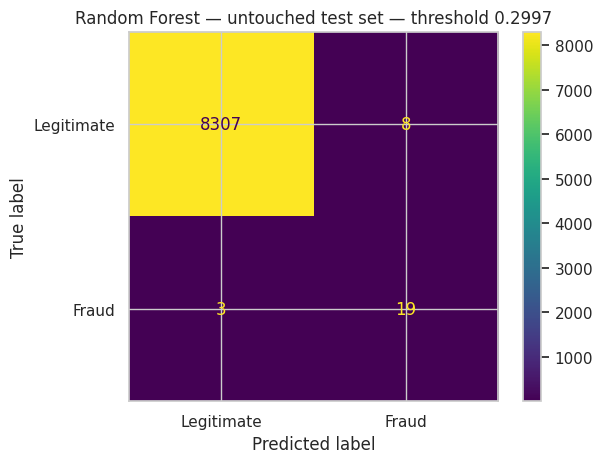

In [ ]:
final_candidates = dict(candidate_scores)
final_candidates["Random Forest"] = tuned_rf_val_scores

final_rows, final_thresholds = [], {}
for name, scores in final_candidates.items():
    thr, _ = choose_threshold_for_f2(y_val, scores)
    final_thresholds[name] = thr
    row = metrics_at_threshold(y_val, scores, thr)
    row["model"] = name
    final_rows.append(row)

final_validation_table = pd.DataFrame(final_rows).set_index("model").sort_values("pr_auc", ascending=False)
display(final_validation_table.round(4))

final_model_name = final_validation_table.index[0]
final_threshold = final_thresholds[final_model_name]
model_lookup = {**fitted_models,
                "Logistic Regression": smote_lr,
                "Random Forest": tuned_rf}
if final_model_name == "":
    final_model = iso_pipeline
    # Isolation Forest has a separate score calculation path.
else:
    final_model = model_lookup[final_model_name]

print("Final selected model:", final_model_name)
print("Final threshold:", final_threshold)

if final_model_name == "Isolation Forest":
    X_test_imp = iso_pipeline.named_steps["imputer"].transform(X_test)
    X_test_scaled = iso_pipeline.named_steps["scaler"].transform(X_test_imp)
    raw_test = -iso_pipeline.named_steps["model"].score_samples(X_test_scaled)
    test_scores = (raw_test - iso_raw.min()) / (iso_raw.max() - iso_raw.min() + 1e-12)
else:
    test_scores = get_scores(final_model, X_test)

test_metrics = evaluate_predictions(
    final_model_name + " — untouched test set",
    y_test, test_scores, final_threshold
)

## 17. Cost-sensitive interpretation
A false negative is a fraudulent transaction incorrectly accepted. A false positive is a legitimate transaction incorrectly flagged. The following table makes those trade-offs visible. The cost values are illustrative only; replace them with values justified by your project assumptions.

In [ ]:
test_pred = (test_scores >= final_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0,1]).ravel()

COST_FALSE_NEGATIVE = 5000  # illustrative units, not real bank loss
COST_FALSE_POSITIVE = 100   # illustrative manual-review cost

estimated_cost = fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE
print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")
print(f"Illustrative cost = {estimated_cost:,.0f} units")
print("Change the two cost assumptions and justify them in your report.")

TN=8,307 | FP=8 | FN=3 | TP=19
Illustrative cost = 15,800 units
Change the two cost assumptions and justify them in your report.


## 18. Calibration check
A model can rank transactions well but still produce poorly calibrated probabilities. This reliability diagram is descriptive; it does not change the selected threshold.

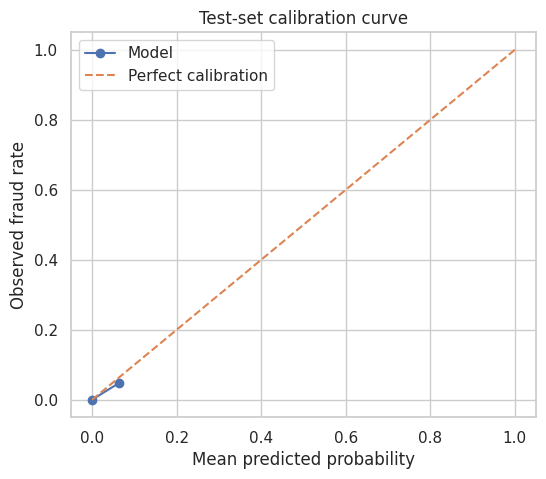

In [ ]:
if final_model_name != "Isolation Forest":
    prob_true, prob_pred = calibration_curve(
        y_test, test_scores, n_bins=10, strategy="quantile"
    )
    plt.figure(figsize=(6,5))
    plt.plot(prob_pred, prob_true, marker="o", label="Model")
    plt.plot([0,1], [0,1], linestyle="--", label="Perfect calibration")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed fraud rate")
    plt.title("Test-set calibration curve")
    plt.legend()
    plt.show()
else:
    print("Skipping probability calibration: Isolation Forest scores are anomaly scores, not calibrated probabilities.")

## 19. Feature importance / explainability
For tree models, display built-in feature importance. For other models, permutation importance can be used. SHAP is attempted for supported tree estimators; it is an explanation tool, not proof of causality.

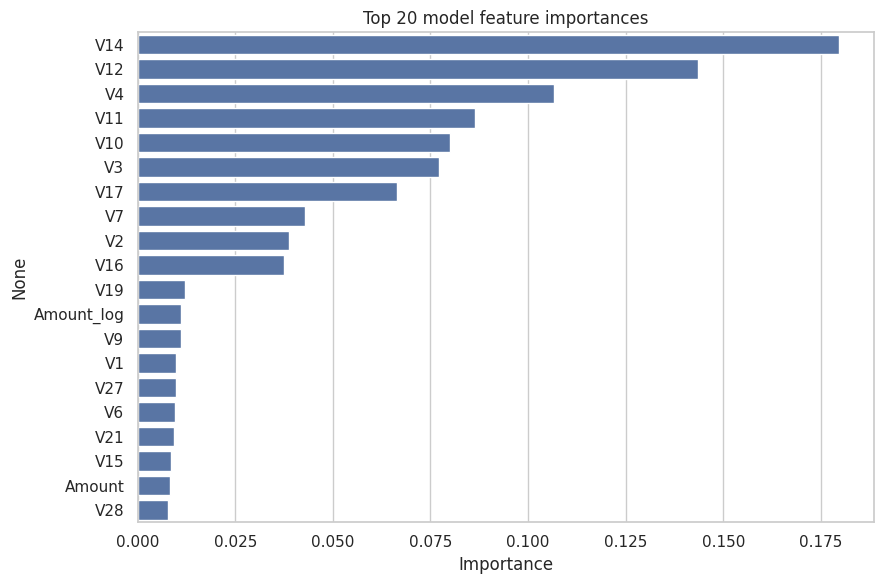

In [ ]:
tree_model = None
if final_model_name in ["Random Forest", "Random Forest", "Decision Tree", "XGBoost"]:
    tree_model = final_model.named_steps["model"]

if tree_model is not None and hasattr(tree_model, "feature_importances_"):
    importances = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(20)
    plt.figure(figsize=(9,6))
    sns.barplot(x=importances.values, y=importances.index)
    plt.title("Top 20 model feature importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    from sklearn.inspection import permutation_importance
    if final_model_name != "Isolation Forest":
        perm = permutation_importance(
            final_model, X_val, y_val, scoring="average_precision",
            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1
        )
        perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(20)
        display(perm_imp.to_frame("permutation_importance"))

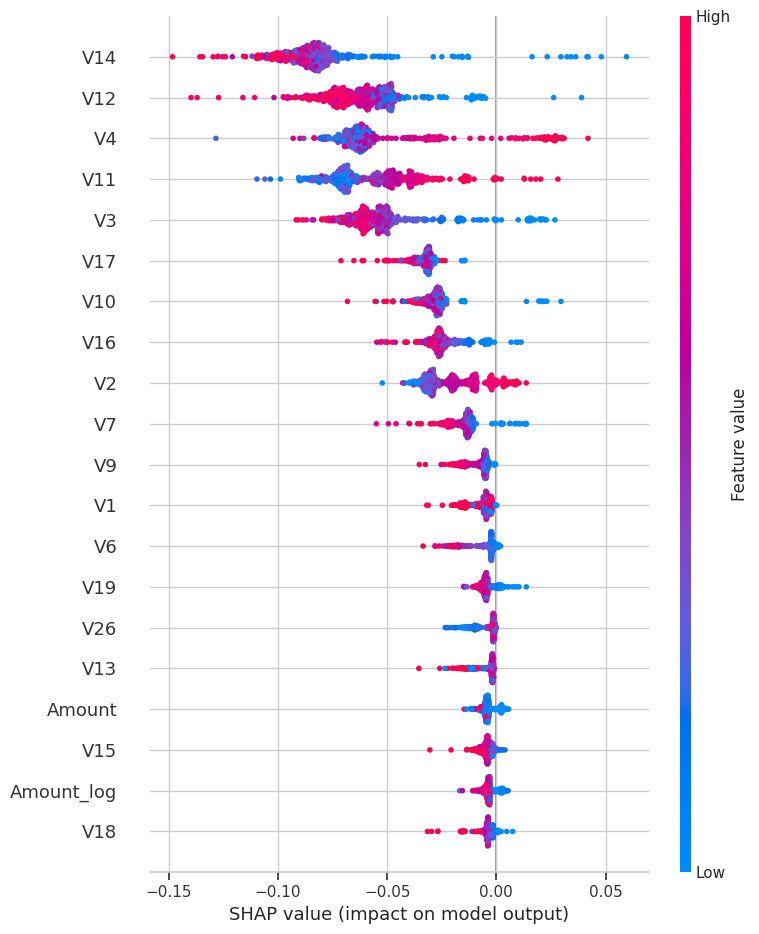

In [ ]:
# Optional SHAP explanation for tree-based final models.
try:
    import shap
    if tree_model is not None:
        X_sample = X_val.sample(min(500, len(X_val)), random_state=RANDOM_STATE)
        X_sample_imp = final_model.named_steps["imputer"].transform(X_sample)
        explainer = shap.TreeExplainer(tree_model)
        shap_values = explainer.shap_values(X_sample_imp)
        if isinstance(shap_values, list):
            shap_to_plot = shap_values[1] if len(shap_values) > 1 else shap_values[0]
        elif getattr(shap_values, "ndim", 0) == 3:
            shap_to_plot = shap_values[:, :, 1]
        else:
            shap_to_plot = shap_values
        shap.summary_plot(shap_to_plot, X_sample, feature_names=list(X.columns))
    else:
        print("SHAP tree explanation skipped because the selected final model is not tree-based.")
except Exception as e:
    print("SHAP could not be generated in this environment:", repr(e))

## 20. Robustness check: feature perturbation
This is a controlled stress test, not a claim that the data represents future fraud. We add small noise to numeric features and measure the change in PR-AUC. Scaling/noise magnitude should be documented in the report.

In [ ]:
if final_model_name != "Isolation Forest":
    X_test_noisy = X_test.copy()
    rng = np.random.default_rng(RANDOM_STATE)
    for col in X_test_noisy.columns:
        if pd.api.types.is_numeric_dtype(X_test_noisy[col]):
            std = X_train[col].std(skipna=True)
            if pd.notna(std) and std > 0:
                X_test_noisy[col] = X_test_noisy[col] + rng.normal(
                    0, 0.01 * std, size=len(X_test_noisy)
                )
    noisy_scores = get_scores(final_model, X_test_noisy)
    clean_ap = average_precision_score(y_test, test_scores)
    noisy_ap = average_precision_score(y_test, noisy_scores)
    print(f"Clean test PR-AUC: {clean_ap:.5f}")
    print(f"Perturbed test PR-AUC: {noisy_ap:.5f}")
    print(f"Change: {noisy_ap-clean_ap:+.5f}")
else:
    print("Perturbation scoring for Isolation Forest can be added separately; skipping to avoid mixing score normalization schemes.")

Clean test PR-AUC: 0.85327
Perturbed test PR-AUC: 0.85866
Change: +0.00539


## 21. Working transaction scoring demo
The demo uses an actual held-out test row as an example. The CSV contains anonymized PCA features (`V1`–`V28` in the common dataset), so users cannot realistically type meaningful values for a brand-new transaction without a compatible upstream feature-generation system.

In [ ]:
def score_transaction(transaction_dict):
    row = pd.DataFrame([transaction_dict])
    # Match training feature order; missing input fields become NaN and are imputed by the fitted pipeline.
    row = row.reindex(columns=X.columns)
    if final_model_name == "Isolation Forest":
        row_imp = iso_pipeline.named_steps["imputer"].transform(row)
        row_scaled = iso_pipeline.named_steps["scaler"].transform(row_imp)
        raw = -iso_pipeline.named_steps["model"].score_samples(row_scaled)
        score = float((raw[0] - iso_raw.min()) / (iso_raw.max() - iso_raw.min() + 1e-12))
    else:
        score = float(get_scores(final_model, row)[0])
    prediction = int(score >= final_threshold)
    return {
        "fraud_score": score,
        "decision": "FLAG AS POTENTIAL FRAUD" if prediction == 1 else "LIKELY LEGITIMATE",
        "threshold": float(final_threshold)
    }

# Demonstrate with one real test transaction (its true label is shown only for demonstration).
demo_index = X_test.index[0]
demo_transaction = X_test.loc[demo_index].to_dict()
print("Demo result:", score_transaction(demo_transaction))
print("Actual dataset label (evaluation only):", int(y_test.loc[demo_index]))

Demo result: {'fraud_score': 0.0, 'decision': 'LIKELY LEGITIMATE', 'threshold': 0.2996527926141599}
Actual dataset label (evaluation only): 0


## 22. Save the trained model and metadata

In [ ]:
# Save model, feature order, threshold and model name for later reuse.
artifact = {
    "model": final_model,
    "model_name": final_model_name,
    "threshold": final_threshold,
    "feature_columns": list(X.columns),
    "feature_engineering": ["Amount_log = log1p(Amount)", "Hour = (Time // 3600) % 24 where source columns exist"]
}
joblib.dump(artifact, "fraud_detection_model.joblib")
print("Saved: fraud_detection_model.joblib")

# Download from Colab
from google.colab import files
files.download("fraud_detection_model.joblib")

Saved: fraud_detection_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Final report checklist

Include these items in your written report and viva:

1. Dataset source, number of rows/features, and class distribution.
2. Why accuracy is not sufficient for imbalanced fraud detection.
3. Why the train/validation/test split is stratified.
4. How preprocessing avoids leakage.
5. Why SMOTE is applied only to training data.
6. Comparison of all models using PR-AUC, recall, precision, F1/F2, and confusion matrices.
7. Why the selected threshold differs from 0.50.
8. False-positive and false-negative trade-offs.
9. Feature-importance/SHAP interpretation and its limitations.
10. Robustness experiment setup and observed result.
11. Limitations: anonymized features, old dataset, possible concept drift, and no live banking integration.
12. Future work: temporal validation, calibrated probabilities, cost-based thresholding, and drift monitoring.

**Academic integrity:** report the values produced by your actual Colab run. Do not invent results or claim the notebook is production-ready. The common Kaggle dataset's anonymized PCA columns make a real-world live transaction interface impossible without the original feature-generation pipeline.